# 5. Head to head: genre, people and screenplays on the same films

**Question.** Which of the three goes most with return, on the same films and the same measure?

**Method.** Three networks on the common set: films sharing a genre, sharing people, or with similar screenplays (each linked to its 10 nearest by cosine similarity of a sentence embedding, all-MiniLM-L6-v2, which is not the Word2Vec of notebook 4). Assortativity of the return beyond films of the same budget decile and era.

**Compared to what?** The same 1,000 shuffles within era bins for all three.

**What it misses.** The networks differ in size: shared genre links almost every film to every other, so this measures genre badly, and notebook 2 measures it better. It isn't causal.

In [1]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "analysis").exists())
A = ROOT / "src" / "analysis"
pd.set_option("display.max_colwidth", 90)

In [2]:
a = pd.read_csv(A / "compare/outputs/head_to_head/assortativity.csv")
a.round(4)

,network,links,n_links,mean_degree,assortativity,null_mean,null_95,p,share_links_sharing_genre
0,genre,all links,726221,908.9,0.0006,-0.0007,0.0005,0.0350,1.000
1,people,all links,33685,42.2,0.0456,-0.0012,0.0073,0.0010,0.664
2,people,links within a shared genre,22377,28.0,0.0490,-0.0012,0.0095,0.0010,0.664
3,people,links with no shared genre,11308,14.2,0.0324,-0.0017,0.0136,0.0020,0.664
4,script,all links,13692,17.1,0.0212,-0.0016,0.0130,0.0060,0.805
5,script,links within a shared genre,11022,13.8,0.0305,-0.0018,0.0142,0.0010,0.805
6,script,links with no shared genre,2670,3.3,-0.0156,-0.0022,0.0298,0.7433,0.805


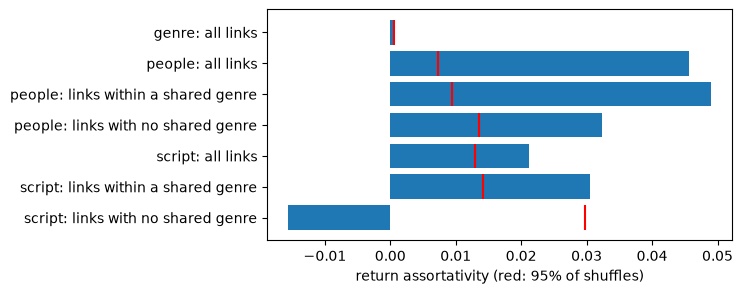

In [3]:
o = a.iloc[::-1]
fig, ax = plt.subplots(figsize=(6, 3))
ax.barh(o.network + ": " + o.links, o.assortativity, color="tab:blue")
ax.vlines(o.null_95, [i - .4 for i in range(len(o))], [i + .4 for i in range(len(o))], color="red")
ax.set_xlabel("return assortativity (red: 95% of shuffles)"); plt.show()